# FEM Practical Exercises · 1.1
## From the model problem to a trustworthy simulation

Nine exercises follow the nine sections of [the theory guide](../README.md).
[Setup](../NOTEBOOK_README.md) · [Exercise guide](README.md)

Work through the tasks, edit the indicated parameter or function cells, and write a short
interpretation after each experiment. Supplied cells give runnable baseline experiments;
they are **not completed answers** to the requested comparisons. Assertions check the
baseline, and the text states what evidence a completed answer should include.

Python 3.11+; CPU / float64. This notebook implements 1D FEM in NumPy/SciPy, independently
of the worked notebooks. Suggested duration: two sessions of 60–90 minutes.


In [1]:
import platform
import numpy as np
import scipy
from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.linalg import eigh
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=4, suppress=True)
SEED = 7
rng = np.random.default_rng(SEED)
palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449"}
plt.rcParams.update({"figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.labelcolor": palette["ink"], "text.color": palette["ink"],
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
    "axes.titleweight": "bold", "grid.alpha": .35, "lines.linewidth": 2.2,
    "figure.dpi": 100, "legend.frameon": False,
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                      ["teal", "orange", "navy", "pink", "blue"]])})
print(f"Python {platform.python_version()} · NumPy {np.__version__} · SciPy {scipy.__version__}")
print("CPU / float64 / deterministic quadrature / seed", SEED)


Python 3.13.9 · NumPy 2.4.2 · SciPy 1.17.0
CPU / float64 / deterministic quadrature / seed 7


In [2]:
# Shared mathematical scaffold, repeated here so this notebook runs independently.
def assemble_p1(nodes, forcing=lambda x: np.zeros_like(x), diffusion=lambda x: np.ones_like(x)):
    """P1 stiffness, consistent mass and load; five-point Gauss quadrature."""
    nodes = np.asarray(nodes, dtype=np.float64)
    assert np.all(np.diff(nodes) > 0)
    z, w = np.polynomial.legendre.leggauss(5)
    phi = np.column_stack(((1-z)/2, (1+z)/2))
    rows, cols, stiffness, mass = [], [], [], []
    load = np.zeros(len(nodes))
    for e, h in enumerate(np.diff(nodes)):
        q = nodes[e] + (z+1)*h/2
        ke = np.array([[1., -1.], [-1., 1.]]) * np.dot(w, diffusion(q))/(2*h)
        me = h/6 * np.array([[2., 1.], [1., 2.]])
        fe = h/2 * (phi.T @ (w*forcing(q)))
        for i in range(2):
            load[e+i] += fe[i]
            for j in range(2):
                rows.append(e+i); cols.append(e+j)
                stiffness.append(ke[i,j]); mass.append(me[i,j])
    shape = (len(nodes), len(nodes))
    return (sparse.coo_matrix((stiffness, (rows, cols)), shape=shape).tocsr(),
            sparse.coo_matrix((mass, (rows, cols)), shape=shape).tocsr(), load)

def solve_dirichlet(K, load, values=(0., 0.)):
    uh = np.zeros(K.shape[0]); uh[[0,-1]] = values
    uh[1:-1] = spsolve(K[1:-1, 1:-1], load[1:-1] - (K @ uh)[1:-1])
    return uh

def errors_p1(nodes, uh, exact, derivative):
    z, w = np.polynomial.legendre.leggauss(8)
    h = np.diff(nodes)
    q = nodes[:-1,None] + h[:,None]*(z[None,:]+1)/2
    discrete = uh[:-1,None]*(1-z)/2 + uh[1:,None]*(1+z)/2
    gradient = np.diff(uh)/h
    L2_sq = np.sum(h[:,None]/2*w*(discrete-exact(q))**2)
    H1_sq = np.sum(h[:,None]/2*w*(gradient[:,None]-derivative(q))**2)
    return np.sqrt([L2_sq, H1_sq])


## 1 · Motivation and roadmap

**Task.** Starting from $u(x)=\sin(k\pi x)$, derive its forcing and list the PDE,
weak problem, discrete space, matrix system, solver, and verification steps.
Run $k=1,3,7$ with the same 16 elements; then increase the resolution until all
three have relative $L^2$ error below 1%. Report elements per wavelength.

**Hint.** Use $f=(k\pi)^2u$ and $\|u\|_{L^2}=1/\sqrt2$.
**Deliverable.** A table with $k$, element count, relative error, and your stopping rule.


In [3]:
# EDIT: collect at least three frequencies and refine each independently.
frequency, elements = 1, 16
x = np.linspace(0,1,elements+1)
u_exact=lambda x: np.sin(frequency*np.pi*x)
du_exact=lambda x: frequency*np.pi*np.cos(frequency*np.pi*x)
f=lambda x: (frequency*np.pi)**2*u_exact(x)
K,M,b=assemble_p1(x,f); uh=solve_dirichlet(K,b)
relative_error=np.sqrt(2)*errors_p1(x,uh,u_exact,du_exact)[0]
print(f"k={frequency}, elements={elements}, relative L2 error={relative_error:.3%}")
assert np.isfinite(relative_error)


k=1, elements=16, relative L2 error=0.352%


## 2 · Weak formulations and well-posedness

**Task.** Replace $a(x)=1$ by $a(x)=\varepsilon+x$ for
$\varepsilon=1,10^{-1},10^{-3}$ and manufacture $f=-(au')'$ for $u=\sin(\pi x)$.
Explain where continuity and coercivity enter the weak formulation. Compare the
smallest eigenvalue and condition number of the constrained stiffness matrices.
Then explain why a pure Neumann problem requires compatibility and a gauge.

**Hint.** $f=a\pi^2\sin(\pi x)-\pi\cos(\pi x)$.
The smallest matrix eigenvalue uses the Euclidean coefficient norm; do not identify
it directly with the continuous coercivity constant.


In [4]:
# EDIT: sweep epsilon; derive the source before modifying either expression.
epsilon=1.
a=lambda x: epsilon+x
f_variable=lambda x: a(x)*np.pi**2*np.sin(np.pi*x)-np.pi*np.cos(np.pi*x)
x=np.linspace(0,1,33)
Kv,Mv,bv=assemble_p1(x,f_variable,a)
eigs=np.linalg.eigvalsh(Kv[1:-1,1:-1].toarray())
print("Smallest eigenvalue / condition number:",eigs[0],eigs[-1]/eigs[0])
assert eigs[0] > 0
# Before boundary constraints, constants lie in the kernel.
assert np.linalg.norm(Kv @ np.ones(len(x))) < 1e-10


Smallest eigenvalue / condition number: 0.4477090304886357 520.1412892332191


## 3 · Galerkin approximation

**Task.** Verify Galerkin orthogonality with five random test functions and compare
the energy of $u_h$, its nodal interpolant, and perturbed coefficient vectors.
Use variable diffusion so that the interpolant need not equal the Galerkin solution.
Explain how this experiment illustrates Céa's lemma without proving it.

**Check.** Every discrete perturbation with zero boundary values should increase energy,
and its first-order cross term should vanish to solver accuracy.


In [5]:
# EDIT: add five perturbations and compare with the interpolant of sin(pi*x).
uh=solve_dirichlet(Kv,bv)
vh=rng.normal(size=len(x)); vh[[0,-1]]=0
energy=lambda w: .5*w @ (Kv @ w)-bv @ w
print("Orthogonality defect:",vh @ (Kv @ uh-bv))
print("Energy increment:",energy(uh+.1*vh)-energy(uh))
assert abs(vh @ (Kv @ uh-bv)) < 1e-9
assert energy(uh+.1*vh) >= energy(uh)-1e-12


Orthogonality defect: -3.410627153700513e-14
Energy increment: 9.775369340455796


## 4 · Meshes and finite element spaces

**Task.** Compare uniform and graded meshes $x_i=(i/N)^\gamma$ for
$\gamma=1,2,4$. Plot three hat basis functions, calculate the largest-to-smallest
cell ratio, and map a reference hat onto a chosen physical cell. State why these
spaces are conforming in $H^1$ and why a discontinuous piecewise constant space is not.
Extend the reference-element sketch to P2 and count the extra degrees of freedom.

**Check.** The hats form a partition of unity, including the endpoint hats.


Cell-size ratio: 31.0


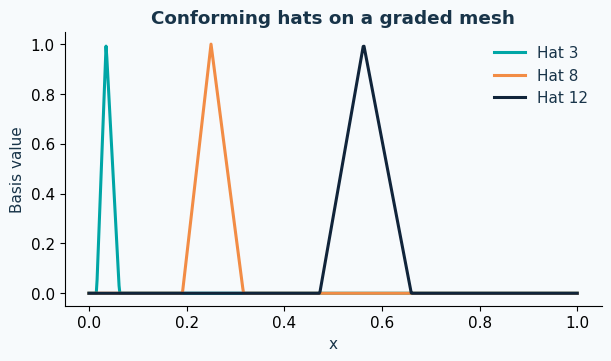

In [6]:
# EDIT: repeat gamma values, select three interior hats, and draw the reference map.
gamma=2.; mesh_nodes=np.linspace(0,1,17)**gamma
sample=np.linspace(0,1,601)
hats=np.array([np.interp(sample,mesh_nodes,np.eye(len(mesh_nodes))[j]) for j in range(len(mesh_nodes))])
assert np.allclose(hats.sum(axis=0),1.)
print("Cell-size ratio:",np.diff(mesh_nodes).max()/np.diff(mesh_nodes).min())
fig,ax=plt.subplots(figsize=(6,3.5),layout="constrained")
for j in [3,8,12]: ax.plot(sample,hats[j],label=f"Hat {j}")
ax.set(xlabel="x",ylabel="Basis value",title="Conforming hats on a graded mesh");ax.legend();plt.show()


## 5 · Assembly and discrete systems

**Task.** Assemble a three-element problem by hand and compare every entry with
`assemble_p1`. Impose $u(0)=1,u(1)=2$. Deliberately omit the boundary lift on a copy
of the system, then use the free-DOF residual to diagnose the error.

**Hint.** A global node belongs to two cells, so diagonal entries receive two contributions.
**Deliverable.** Hand matrices, corrected code, and a sentence explaining the failed check.


In [7]:
small_x=np.linspace(0,1,4)
Ks,Ms,bs=assemble_p1(small_x,lambda x: np.ones_like(x))
us=solve_dirichlet(Ks,bs,values=(1.,2.))
print("K =\n",Ks.toarray(),"\nb =",bs,"\nu =",us)
assert np.linalg.norm((Ks @ us-bs)[1:-1]) < 1e-12
# EDIT: enter your hand-assembled arrays and compare with np.allclose.


K =
 [[ 3. -3.  0.  0.]
 [-3.  6. -3.  0.]
 [ 0. -3.  6. -3.]
 [ 0.  0. -3.  3.]] 
b = [0.1667 0.3333 0.3333 0.1667] 
u = [1.     1.4444 1.7778 2.    ]


## 6 · Error estimates and convergence

**Task.** Measure both error norms on at least four meshes. First use a smooth
sine, then use $u=x^\beta-x$ with $\beta=1.25$; derive the new forcing.
Compare observed rates with the regularity available in each case. Explain how a
reentrant corner in two dimensions can create the same loss of regularity.

**Hint.** $f=-\beta(\beta-1)x^{\beta-2}$; increase quadrature near $x=0$
if the measured rates depend noticeably on the quadrature order.
**Check.** Do not replace integrated errors by nodal differences.


In [8]:
# EDIT: add refinement levels and the reduced-regularity manufactured solution.
error_rows=[]
for n in [8,16]:
    xn=np.linspace(0,1,n+1)
    Kn,_,bn=assemble_p1(xn,lambda x: np.pi**2*np.sin(np.pi*x))
    un=solve_dirichlet(Kn,bn)
    error_rows.append((1/n,*errors_p1(xn,un,lambda x:np.sin(np.pi*x),lambda x:np.pi*np.cos(np.pi*x))))
error_rows=np.array(error_rows)
print("h / L2 / H1 seminorm:\n",error_rows)
print("Observed rates:",np.log2(error_rows[:-1,1:]/error_rows[1:,1:]))


h / L2 / H1 seminorm:
 [[0.125  0.0099 0.2512]
 [0.0625 0.0025 0.1258]]
Observed rates: [[1.9964 0.9972]]


## 7 · A posteriori estimation and adaptivity

**Task.** Use the supplied residual indicator for a localized forcing, perform
five solve–estimate–mark–refine cycles, and compare against uniform meshes at equal
DOFs. Repeat marking fractions 0.3 and 0.8. Distinguish the error indicator from
an error bound whose reliability constant is known.

**Hint.** Use the manufactured Gaussian in Laboratory 02 if you need true errors.
**Check.** Refinement must preserve endpoints and positive cell lengths.


In [9]:
def residual_indicators(nodes, uh, forcing):
    """1D residual indicator: cell h²||f||² plus shared derivative jumps."""
    h = np.diff(nodes)
    z, w = np.polynomial.legendre.leggauss(8)
    q = nodes[:-1,None] + h[:,None]*(z+1)/2
    eta2 = h**3/2 * np.sum(w*forcing(q)**2, axis=1)
    jumps = np.diff(np.diff(uh)/h)
    eta2[:-1] += .5*h[:-1]*jumps**2
    eta2[1:] += .5*h[1:]*jumps**2
    return eta2

def mark_and_refine(nodes, eta2, fraction=.5):
    assert 0 < fraction <= 1
    order = np.argsort(eta2)[::-1]
    count = np.searchsorted(np.cumsum(eta2[order]), fraction*eta2.sum())+1
    marked = order[:count]
    midpoints = (nodes[marked]+nodes[marked+1])/2
    return np.sort(np.concatenate((nodes, midpoints)))


In [10]:
# EDIT: wrap this baseline cycle in a loop and collect error-versus-DOF records.
xa=np.linspace(0,1,17)
localized=lambda x: 100*np.exp(-500*(x-.37)**2)
Ka,_,ba=assemble_p1(xa,localized); ua=solve_dirichlet(Ka,ba)
eta2=residual_indicators(xa,ua,localized)
refined=mark_and_refine(xa,eta2,fraction=.5)
assert refined[0]==0 and refined[-1]==1 and np.all(np.diff(refined)>0)
print("Old / new element counts:",len(xa)-1,len(refined)-1)


Old / new element counts: 16 17


## 8 · Evolution PDEs: space and time

**Task.** Measure the generalized eigenvalue stability limit. Compare forward
Euler just below and just above it, then compare backward Euler with Crank–Nicolson
at a larger time step. Use a small high-frequency perturbation and plot discrete
$L^2$ energy. Design a second experiment separating time error from spatial error.

**Check.** For zero forcing and $\theta\ge1/2$, energy should not increase.
**Reflection.** Can a stable solution still be inaccurate or oscillatory?


In [11]:
def theta_heat(n=32, theta=1., dt=.002, final_time=.04, high_frequency=.0):
    x = np.linspace(0, 1, n+1)
    K, M, _ = assemble_p1(x)
    Ki, Mi = K[1:-1,1:-1], M[1:-1,1:-1]
    steps = max(1, int(np.ceil(final_time/dt))); dt = final_time/steps
    u0 = np.sin(np.pi*x[1:-1]) + high_frequency*np.sin((n-1)*np.pi*x[1:-1])
    A = (Mi+theta*dt*Ki).tocsc()
    solve = sparse.linalg.factorized(A)
    B = Mi-(1-theta)*dt*Ki
    u = u0.copy(); energies = [.5*u @ (Mi @ u)]
    for _ in range(steps):
        u = solve(B @ u)
        energies.append(.5*u @ (Mi @ u))
    result = np.zeros(n+1); result[1:-1] = u
    return x, result, np.linspace(0,final_time,steps+1), np.array(energies), dt


Forward Euler dt limit: 0.000293080971224953 chosen dt: 0.002


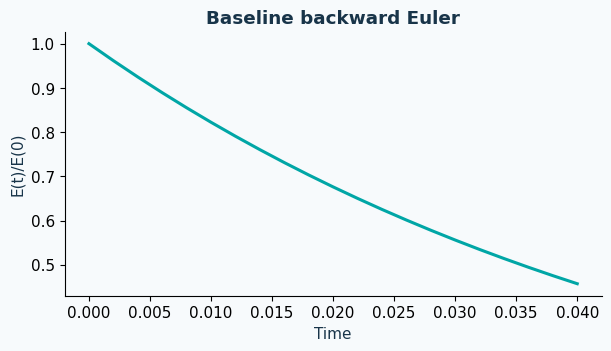

In [12]:
# EDIT: compare theta=0, 0.5, 1 and at least three time-step sizes.
xh,uh,t,E,used_dt=theta_heat(n=24,theta=1.,dt=.002,high_frequency=1e-4)
Kh,Mh,_=assemble_p1(xh)
lmax=eigh(Kh[1:-1,1:-1].toarray(),Mh[1:-1,1:-1].toarray(),eigvals_only=True)[-1]
print("Forward Euler dt limit:",2/lmax,"chosen dt:",used_dt)
assert np.max(np.diff(E)) < 1e-12
fig,ax=plt.subplots(figsize=(6,3.4),layout="constrained")
ax.plot(t,E/E[0]);ax.set(xlabel="Time",ylabel="E(t)/E(0)",title="Baseline backward Euler");plt.show()


## 9 · Checking the solution

**Task.** Design a verification report for one of your earlier experiments.
Include boundary data, free-DOF residual, independent quadrature, convergence,
physical consistency, and the time or memory budget. Introduce one deliberate
bug and show which check detects it. Explain which checks would **not** detect it.

Use the template below; a complete answer must replace each unfinished entry with
numerical evidence or a justified explanation. Passing the supplied assertions alone
does not complete the practical exercises.


In [13]:
report={"problem_and_units":"", "boundary_check":"", "residual_check":"",
        "independent_error_check":"", "refinement_evidence":"",
        "deliberate_bug_and_detector":"", "remaining_limitations":""}
# EDIT: fill each entry after completing your experiments.
print("Entries still to document:",[name for name,value in report.items() if not value])


Entries still to document: ['problem_and_units', 'boundary_check', 'residual_check', 'independent_error_check', 'refinement_evidence', 'deliberate_bug_and_detector', 'remaining_limitations']
